# Decision Trees, Bagging and Random Forests Demo

*The code follows the "Example", "Random Forest Regression" and "Boosting (cont.)" slides of the lecture. The examples on those slides come from Jake VanderPlas, Python Data Science Handbook, section "In Depth: Decision Trees and Random Forests" (code under the MIT licence), and from the scikit-learn documentation of `GradientBoostingClassifier`.*

**Problem:** a single decision tree over-fits: its decision regions follow the noise in the training data. We compare it with an ensemble of trees built by **bagging** and with a **random forest**, use a random forest for a non-linear **regression** problem, and run the **boosting** example of the lecture.

**How to run:** this notebook runs in your browser on the course website. Use **Run → Run All Cells**, or press **Shift+Enter** to run one cell at a time, in order. The first run loads scikit-learn and Matplotlib, which takes a few seconds.

**Expected result:** a single tree draws thin, ragged regions between the classes; two trees trained on different halves of the data disagree in those places; the bagged trees and the random forest give smoother regions. The random forest regression follows the wavy curve closely, and gradient boosting reaches a test accuracy of 0.913 on the `make_hastie_10_2` data, as on the slide.

## 1. Imports
NumPy holds the data, Matplotlib draws the plots, and scikit-learn provides the example data and the models.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_hastie_10_2
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier
import warnings
# in the browser, a helper library of scikit-learn prints a harmless deprecation warning; hide it
warnings.filterwarnings("ignore", message="JsProxy.as_object_map", category=RuntimeWarning)

## 2. The data
`make_blobs` creates 300 points in four groups (classes). The groups overlap a little, so a classifier cannot separate them perfectly.

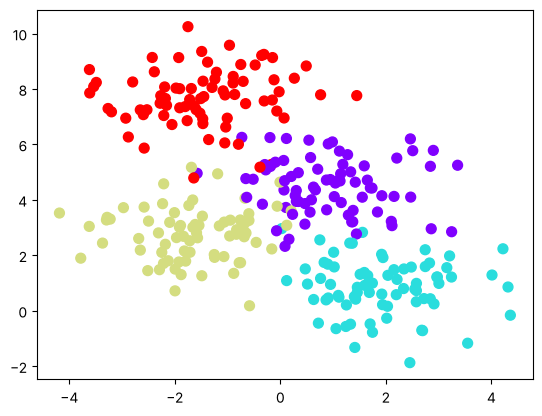

In [2]:
X, y = make_blobs(n_samples=300, centers=4, random_state=0, cluster_std=1.0)  # 300 points, 4 classes
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='rainbow')
plt.show()

## 3. A helper that draws decision regions
`visualize_classifier` trains a model, predicts the class of every point on a fine grid and colours the grid by the predicted class. The coloured areas are the model's decision regions; the training points are drawn on top.

In [3]:
def visualize_classifier(model, X, y, ax=None, cmap='rainbow'):
    ax = ax or plt.gca()

    # Plot the training points
    ax.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=cmap, clim=(y.min(), y.max()), zorder=3)
    ax.axis('tight')
    ax.axis('off')
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # fit the estimator, then predict the class of every point of a 200 x 200 grid
    model.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(*xlim, num=200), np.linspace(*ylim, num=200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Create a color plot with the results
    n_classes = len(np.unique(y))
    ax.contourf(xx, yy, Z, alpha=0.3, levels=np.arange(n_classes + 1) - 0.5, cmap=cmap, zorder=1)
    ax.set(xlim=xlim, ylim=ylim)

## 4. One decision tree
A tree grown until every leaf is pure follows single points: look for the thin strips and small islands of colour between the groups. This is over-fitting.

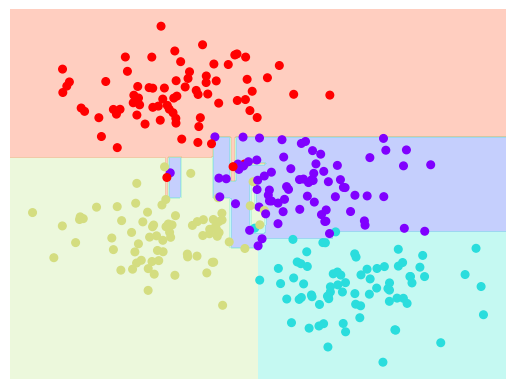

In [4]:
visualize_classifier(DecisionTreeClassifier(random_state=0), X, y)
plt.show()

## 5. Two trees, each trained on half of the data
If the tree really learned the structure of the data, two trees trained on different random halves would draw the same regions. They agree far from the class boundaries but disagree near them, where they follow the noise of their own half.

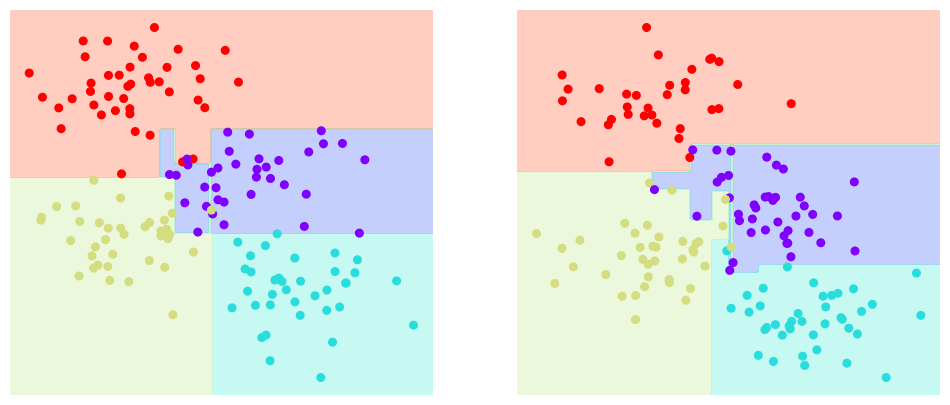

In [5]:
rng = np.random.RandomState(0)
idx = rng.permutation(len(X))             # shuffle the points
half1, half2 = idx[:150], idx[150:]       # two random halves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, part in zip(axes, [half1, half2]):
    visualize_classifier(DecisionTreeClassifier(random_state=0), X[part], y[part], ax=ax)
plt.show()

## 6. Bagging: 100 trees on random subsets
`BaggingClassifier` trains 100 trees, each on 240 points drawn at random with replacement (`max_samples=0.8`: 80% of the 300 points), and lets them vote. The disagreements of the single trees average out, so the regions become smoother.

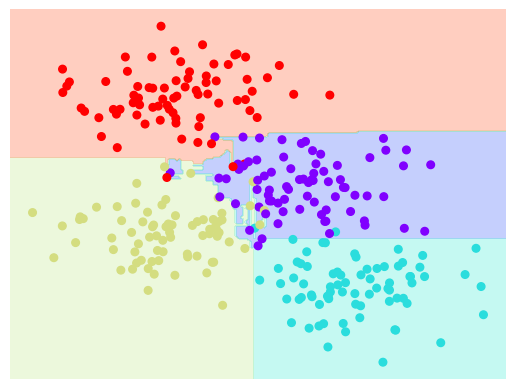

In [6]:
tree = DecisionTreeClassifier()
bag = BaggingClassifier(tree, n_estimators=100, max_samples=0.8, random_state=1)  # 100 trees, 80% of the points each
visualize_classifier(bag, X, y)
plt.show()

## 7. Random forest
`RandomForestClassifier` does the bagging for us (each tree gets a bootstrap sample of the data) and adds a second source of randomness: at every split a tree only considers a random subset of the features.

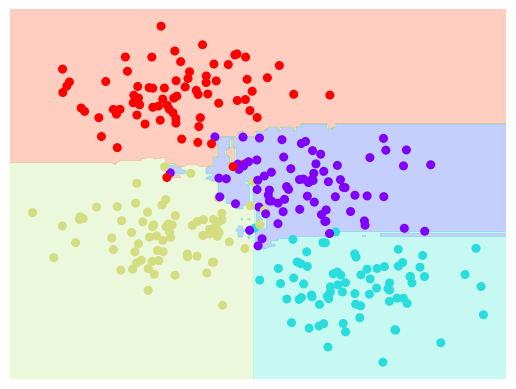

In [7]:
model = RandomForestClassifier(n_estimators=100, random_state=0)  # 100 randomized trees
visualize_classifier(model, X, y)
plt.show()

## 8. Random forest regression
The data are a slow sine wave plus a fast one plus noise, a non-linear regression problem. A forest of 200 regression trees predicts `y` from `x`; the red line is the forest's prediction and the grey line is the true curve without noise.

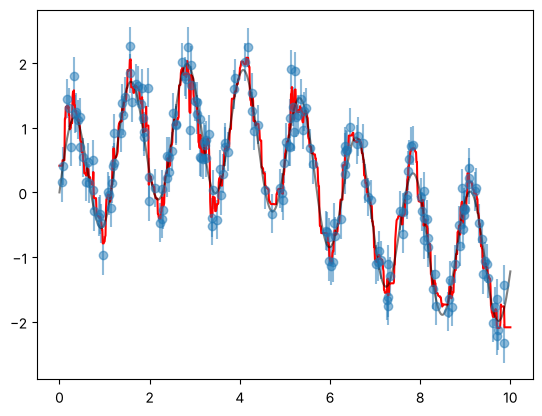

In [8]:
rng = np.random.RandomState(42)
x = 10 * rng.rand(200)

def model(x, sigma=0.3):
    fast_oscillation = np.sin(5 * x)
    slow_oscillation = np.sin(0.5 * x)
    noise = sigma * rng.randn(len(x))
    return slow_oscillation + fast_oscillation + noise

y = model(x)

forest = RandomForestRegressor(200)       # 200 regression trees
forest.fit(x[:, None], y)                 # x[:, None] turns x into a one-column table

xfit = np.linspace(0, 10, 1000)
yfit = forest.predict(xfit[:, None])
ytrue = model(xfit, sigma=0)              # the curve without noise

plt.errorbar(x, y, 0.3, fmt='o', alpha=0.5)
plt.plot(xfit, yfit, '-r')
plt.plot(xfit, ytrue, '-k', alpha=0.5)
plt.show()

## 9. Boosting
The "Boosting (cont.)" slide shows this example from the scikit-learn documentation. `GradientBoostingClassifier` grows 100 very small trees (`max_depth=1`, a single split each) one after the other; each new tree corrects the mistakes of the trees before it. The data have 10 features and 2 classes; the first 2,000 points are used for training and the other 10,000 for testing.

In [9]:
X, y = make_hastie_10_2(random_state=0)
X_train, X_test = X[:2000], X[2000:]
y_train, y_test = y[:2000], y[2000:]

clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0,
    max_depth=1, random_state=0).fit(X_train, y_train)  # 100 one-split trees, grown sequentially
clf.score(X_test, y_test)  # accuracy on the test data

0.913

**Try it:** in section 7, change `n_estimators=100` to `n_estimators=5` and run the cell again. What happens to the decision regions?

<details>
<summary>Show the answer</summary>

With only 5 trees the vote is noisy again: the regions show more thin strips and islands, closer to the single tree of section 4. Averaging over many trees is what smooths the regions, which is why random forests usually use 100 trees or more.
</details>